In [1]:
import muspan as ms
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import os 
import json
from sklearn.cluster import KMeans
import argparse

In [2]:
csv_directory = r"D:\Muspan_temp\csvs"
domain_save = r"D:\Muspan_temp\ROI_domains"
csvs = sorted([f for f in os.listdir(csv_directory) if f.lower().endswith(".csv") and not f.lower().startswith("._")])
    
domains = []
samples = {}
    
required = ["Cell X Position", "Cell Y Position", "Phenotype", "Parent"]

for _, csv in enumerate(csvs):
    csv_path = os.path.join(csv_directory,csv)

    df = pd.read_csv(csv_path)
    ROIs = df['Parent'].unique()

    samples[csv] = len(ROIs)

    for i, ROI in enumerate(ROIs):
        subdf = df.loc[df['Parent'] == ROI]

        # add some control over csv content
        missing = [c for c in required if c not in subdf.columns]
        if missing:
            raise ValueError(f"{csv} missing columns: {missing}")

        points = np.asarray([subdf["Cell X Position"], subdf["Cell Y Position"]])
        points[1,:] = -points[1,:]
        domain = ms.domain(str(csv)+"_"+str(ROI))
        domain.add_points(points.T, "Cell centres")
        domain.add_labels("Phenotype", subdf["Phenotype"])
        domain.add_labels("ROI", subdf["Parent"])
        domains.append(domain)

        ms.io.save_domain(domain, path_to_save=domain_save, name_of_file= str(domain.name))

Domain updated_RADIO TN04 CAF 36781-20-B1 Rx s6_Scan1_Stitched.csv_ROI 5 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_RADIO TN04 CAF 36781-20-B1 Rx s6_Scan1_Stitched.csv_ROI 3 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_RADIO TN04 CAF 36781-20-B1 Rx s6_Scan1_Stitched.csv_ROI 1 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_RADIO TN04 CAF 36781-20-B1 Rx s6_Scan1_Stitched.csv_ROI 4 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_RADIO TN06 CAF 17460-21-A1 Rx s6_Scan1_Stitched.csv_ROI 3 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_RADIO TN06 CAF 17460-21-A1 Rx s6_Scan1_Stitched.csv_ROI 1 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_RADIO TN06 CAF 17460-21-A1 Rx s6_Scan1_Stitched.csv_ROI 7 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_RADIO TN06 CAF 17460-21-A1 Rx s6_Scan1_Stitched.csv_ROI 6 saved successfully to D:\Muspan_temp\ROI_domains.
Domain updated_R

In [3]:
# Helper function for saving matrices as json
def convert_to_serializable(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {k: convert_to_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_serializable(i) for i in obj]
    return obj

In [4]:
clusters_of_interest= ['CD8', 'PDPN', 'FAP']
alpha_var = [50, 100, 1000, 10000]
KLdist_total = []

count = 0

os.makedirs(r"C:\Users\ewestlund\Documents\GitHub Projects\MuSpAn---HPC\KL_dist", exist_ok=True)
save_dir = r"C:\Users\ewestlund\Documents\GitHub Projects\MuSpAn---HPC\KL_dist"

for s, sample in enumerate(list(samples.keys())):
    print(f"Processing {sample}")
    KLdist_sample = []

    for r in range(samples[sample]):
        print(f"ROI count {r}")
        kde_maps = []
        domain = domains[count+r]
        
        categories =domain.labels['Phenotype']['categories'].tolist()
        if not all(cluster in categories for cluster in clusters_of_interest):
            print(f"Not all clusters in domain {domain.name}. Skipping ROI.")
            continue

        finding_alpha = False
        a = 0
        while not finding_alpha and a < len(alpha_var):
            alpha = alpha_var[a]
            try:
                domain.estimate_boundary(method = 'alpha shape', alpha_shape_kwargs=dict(alpha=alpha))
                finding_alpha = True
            except:
                a += 1

        if not finding_alpha:
            print(f"Cannot estimate boundary for {domain.name}. Skipping ROI.")
            continue

        if 'Alpha boundary' in domain.collections:
            qBoundary = ms.query(domain, ('collection,'), 'is', 'Alpha boundary')
            domain.delete_objects(qBoundary)

        qPoints = ms.query.query(domain, ('Collection',), 'is', 'Cell centres')

        newIDs = domain.convert_objects(
                population = qPoints,
                collection_name = 'Alpha boundary',
                return_IDs = True,
                object_type = 'shape',
                conversion_method = 'alpha shape',
                conversion_method_kwargs = dict(alpha = 25, internal_boundaries = False)
        )

        qBoundary = ms.query.query(domain, ('collection',), 'is', 'Alpha boundary')

        domain.simplify_shape_boundaries(
                    qBoundary,
                    delete_original_boundary = True,
                    algorithm = 'Visvalingam-Whyatt',
                    epsilon = 1500
        )

    
        domain.estimate_boundary(method='alpha shape', alpha_shape_kwargs=dict(alpha=alpha))
        qBoundary = ms.query.query(domain, ('collection',), 'is', 'Alpha boundary')
        qPoints = ms.query.query(domain, ('Collection',), 'is', 'Cell centres')


        for i, id in enumerate(clusters_of_interest):
            qCluster2 = ms.query.query(domain, ('label', 'Phenotype'), 'is', id)

            kernel_density_matrix = ms.distribution.kernel_density_estimation(
                domain,
                population = qCluster2,
                include_boundaries=qBoundary,
                mesh_step=10,
                bw_method=0.05,
                visualise_output=False
            )

            kde_maps.append(kernel_density_matrix)

        KL_dist = np.zeros((len(clusters_of_interest), len(clusters_of_interest)))

        for i, clusterA in enumerate(clusters_of_interest):
            for j, clusterB in enumerate(clusters_of_interest):
                if j <= i:
                    continue

                qPopA = ms.query.query(domain, ('label', 'Phenotype'), 'is', clusterA)
                qPopB = ms.query.query(domain, ('label', 'Phenotype'), 'is', clusterB)

                KL_dist[i,j] = ms.distribution.kl_divergence(kde_maps[i], kde_maps[j])
        
        matrices_path = os.path.join(save_dir, f"{domain.name}.json") # adding an extension to the filename

        with open(matrices_path, "w+") as f:
            json.dump({"KL_dist_domain":convert_to_serializable(KL_dist)}, f)

        
        KLdist_sample.append(KL_dist)

    count += r+1

    matrices_path = os.path.join(save_dir, f"{sample}.json") # adding an extension to the filename

    with open(matrices_path, "w+") as f:
        json.dump({"KLdist_sample": convert_to_serializable(KLdist_sample)}, f)

    KLdist_total.append(KLdist_sample)   

matrices_path = os.path.join(save_dir, f"{total}.json") # adding an extension to the filename

with open(matrices_path, "w+") as f:
    json.dump({"KLdist_total": convert_to_serializable(KLdist_total)}, f)

Processing updated_RADIO TN04 CAF 36781-20-B1 Rx s6_Scan1_Stitched.csv
ROI count 0
ROI count 1
Not all clusters in domain updated_RADIO TN04 CAF 36781-20-B1 Rx s6_Scan1_Stitched.csv_ROI 3. Skipping ROI.
ROI count 2
ROI count 3
Processing updated_RADIO TN06 CAF 17460-21-A1 Rx s6_Scan1_Stitched.csv
ROI count 0
ROI count 1
ROI count 2


ValueError: Number of dimensions is greater than number of samples. This results in a singular data covariance matrix, which cannot be treated using the algorithms implemented in `gaussian_kde`. Note that `gaussian_kde` interprets each *column* of `dataset` to be a point; consider transposing the input to `dataset`.

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

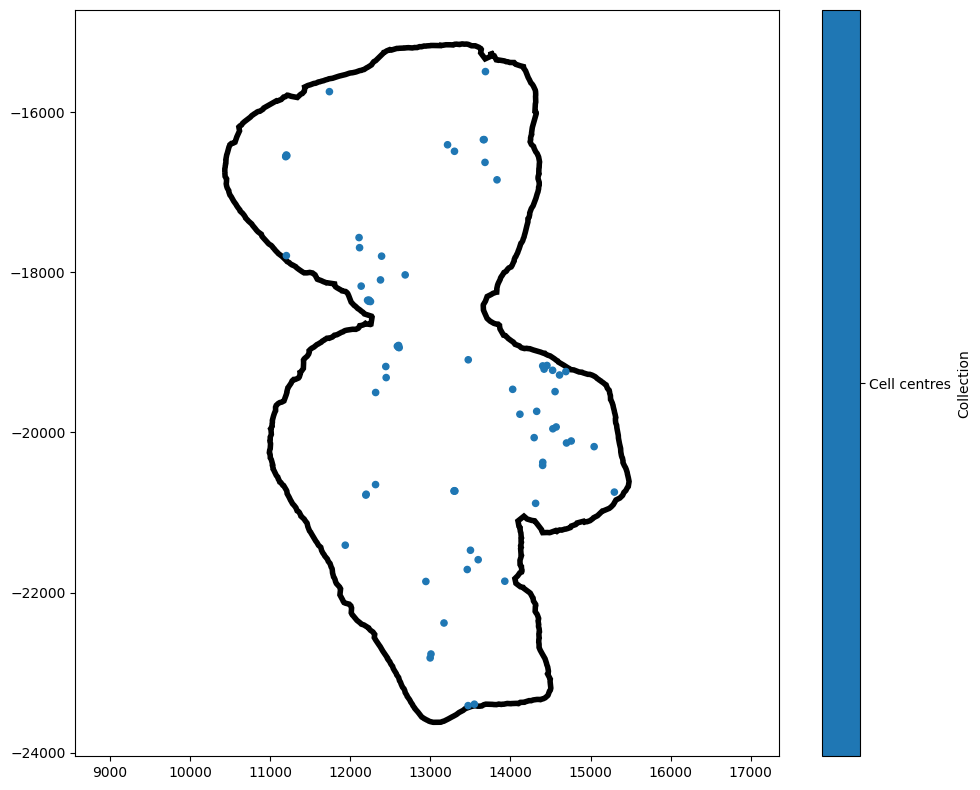

In [10]:
ms.visualise.visualise(domain, objects_to_plot=ms.query.query(domain, ('label', 'Phenotype'), 'is', 'CD8'), show_boundary=True)

In [12]:
domain2 = domains[4]

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

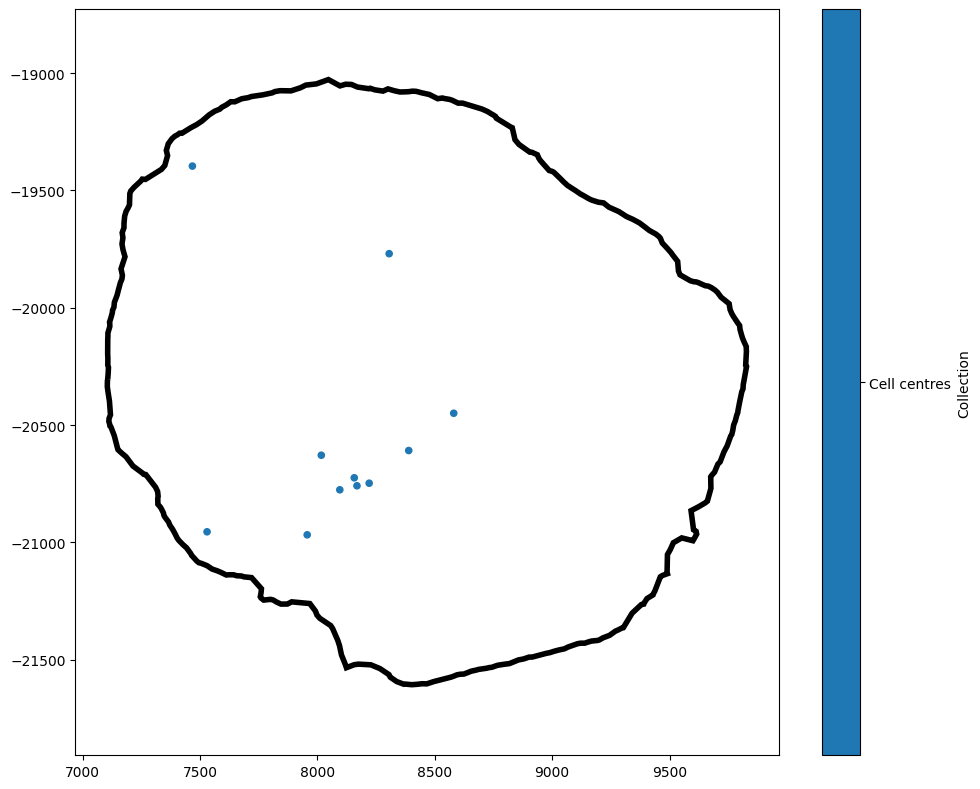

In [13]:
ms.visualise.visualise(domain2, objects_to_plot=ms.query.query(domain, ('label', 'Phenotype'), 'is', 'CD8'), show_boundary=True)

In [24]:
import importlib
import muspan as ms
importlib.reload(ms)

kernel_density_matrix = ms.distribution.kernel_density_estimation(
                domain,
                population = qCluster2,
                include_boundaries=qBoundary,
                mesh_step=10,
                bw_method=0.05,
                visualise_output=False
            )

ValueError: Number of dimensions is greater than number of samples. This results in a singular data covariance matrix, which cannot be treated using the algorithms implemented in `gaussian_kde`. Note that `gaussian_kde` interprets each *column* of `dataset` to be a point; consider transposing the input to `dataset`.